<a href="https://colab.research.google.com/github/anthony-yt/deepwater-image-segmentation-classical-quantum/blob/main/notebooks/1_optical_preprocessing_comparison.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import os
import cv2
from google.colab import drive

drive.mount('/content/drive')

DRIVE_ROOT = "/content/drive/MyDrive/Under_Water_Dataset"
FRAMES_OUT_DIR = os.path.join(DRIVE_ROOT, "Dataset_Processed", "Frames_Crudos")
os.makedirs(FRAMES_OUT_DIR, exist_ok=True)

def extract_video_frames(input_dir: str, output_dir: str, interval_sec: int = 2) -> int:
    """Extract frames from underwater videos at a fixed temporal sampling rate to mitigate redundancy."""
    valid_extensions = ('.mp4', '.avi', '.mov')
    video_files = [f for f in os.listdir(input_dir) if f.lower().endswith(valid_extensions)]
    total_extracted = 0

    for video_name in video_files:
        video_path = os.path.join(input_dir, video_name)
        cap = cv2.VideoCapture(video_path)

        if not cap.isOpened():
            continue

        fps = cap.get(cv2.CAP_PROP_FPS)
        frame_step = int(fps * interval_sec)
        frame_count, saved_count = 0, 0

        while cap.isOpened():
            ret, frame = cap.read()
            if not ret:
                break

            if frame_count % frame_step == 0:
                base_name = os.path.splitext(video_name)[0]
                out_path = os.path.join(output_dir, f"{base_name}_frame_{saved_count:04d}.jpg")
                cv2.imwrite(out_path, frame)
                saved_count += 1
                total_extracted += 1

            frame_count += 1

        cap.release()

    return total_extracted

total_frames = extract_video_frames(DRIVE_ROOT, FRAMES_OUT_DIR, interval_sec=2)
print(f"Extraction completed. Total frames: {total_frames}")

Mounted at /content/drive
Extraction completed. Total frames: 105


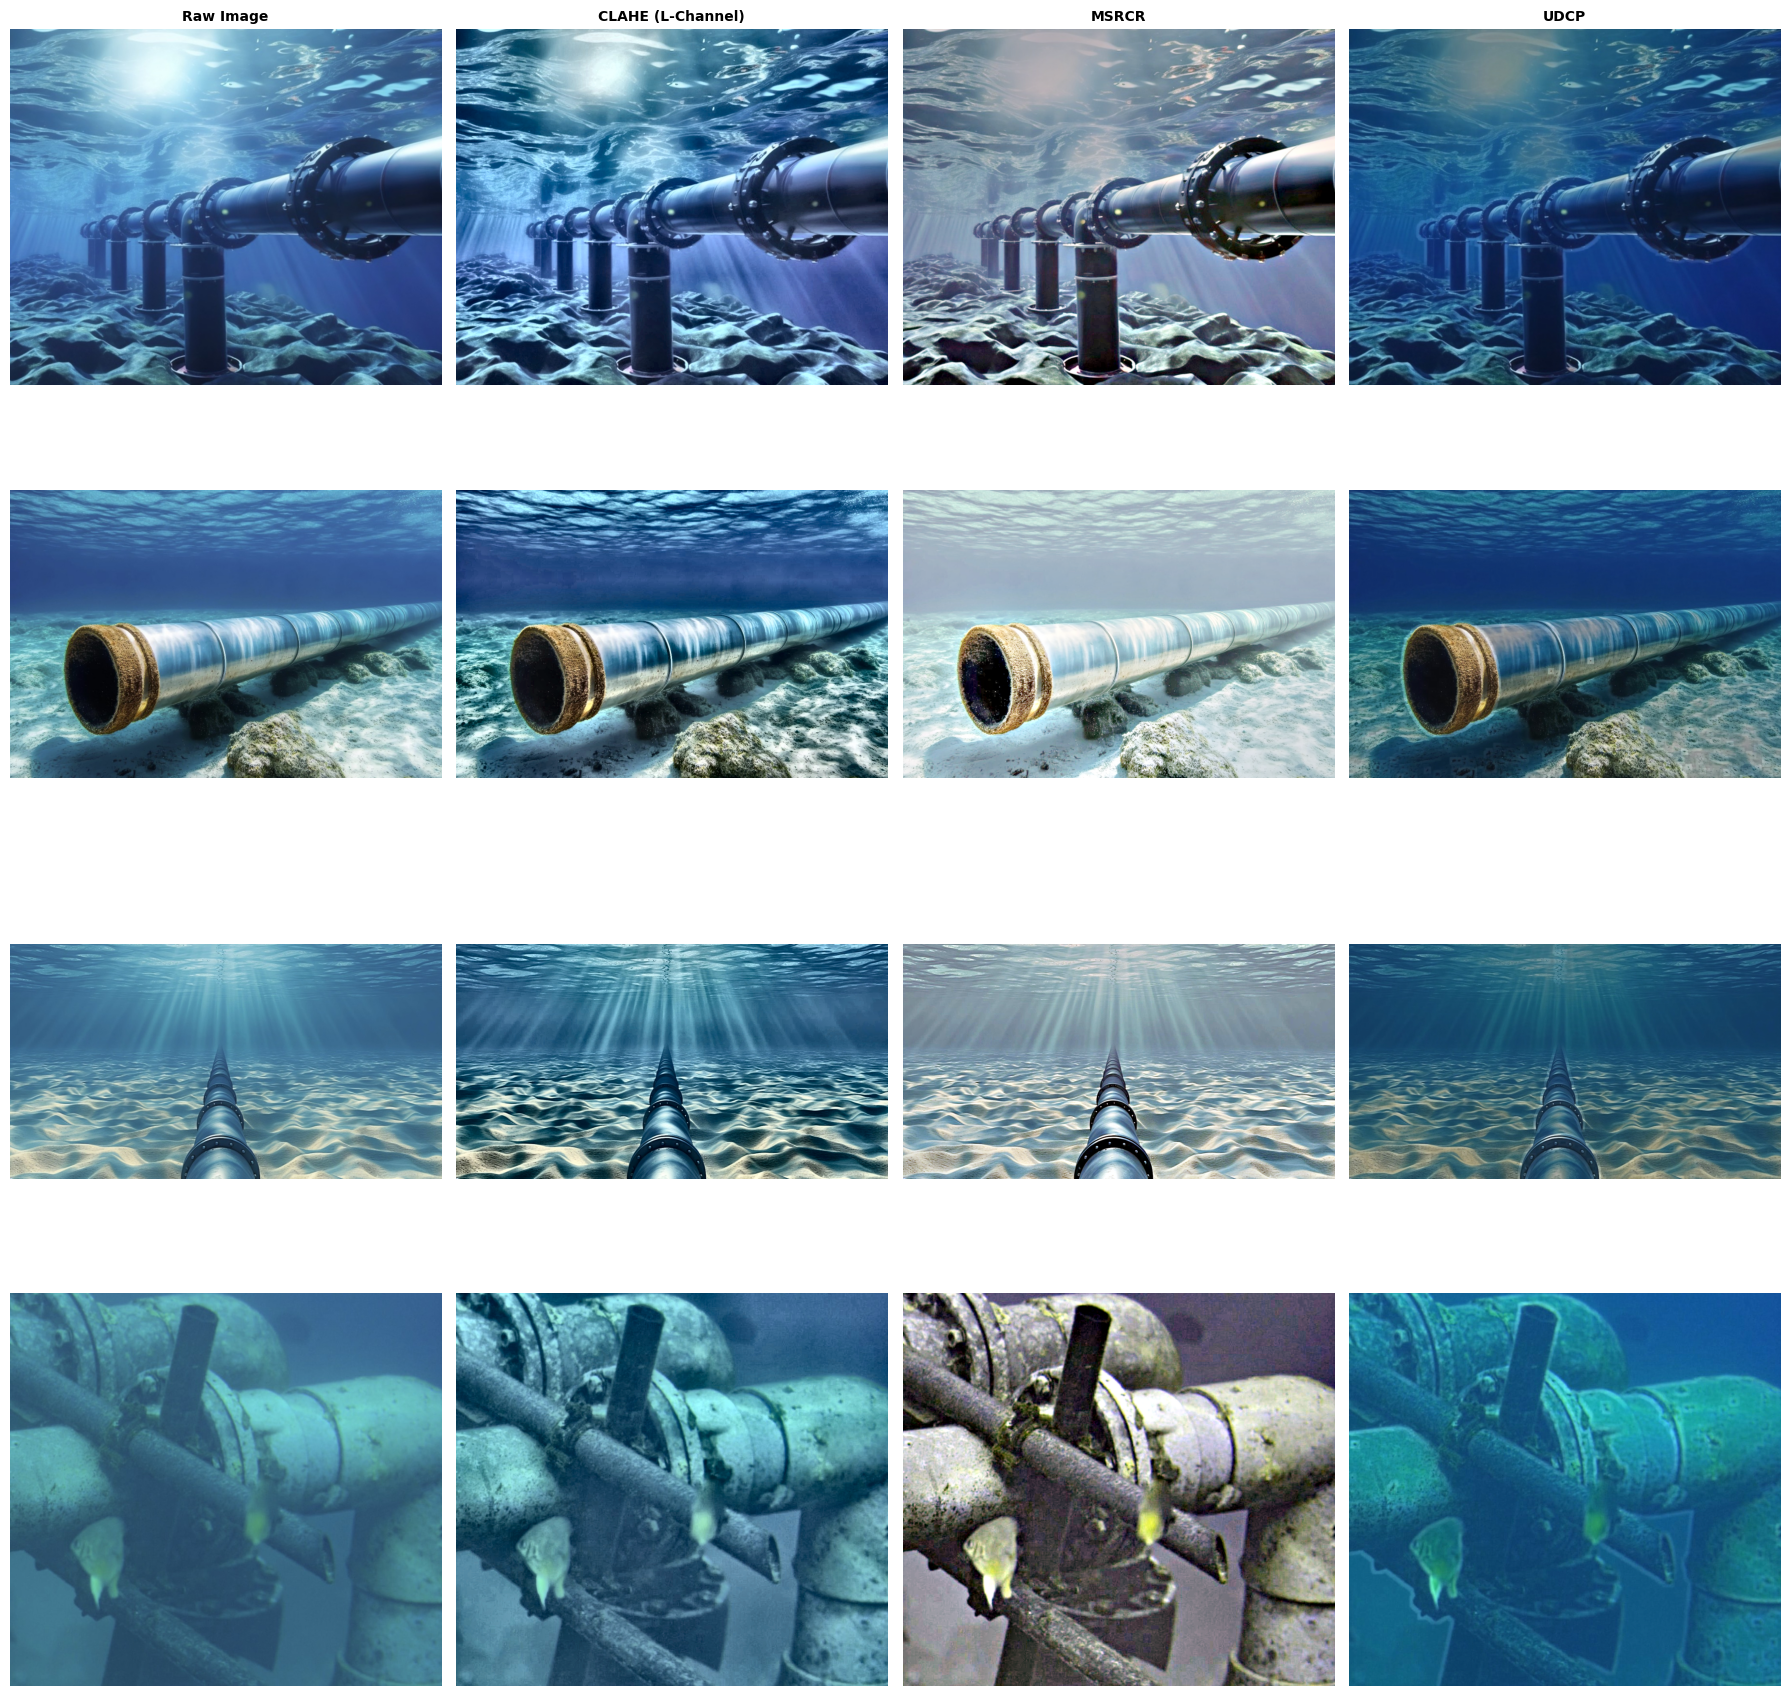

In [3]:
import numpy as np
import matplotlib.pyplot as plt

def apply_clahe(img_bgr: np.ndarray, clip_limit: float = 3.0, grid_size: tuple = (8, 8)) -> np.ndarray:
    """Apply CLAHE solely on the luminance channel (L) in CIELAB space."""
    lab = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2LAB)
    l, a, b = cv2.split(lab)
    clahe = cv2.createCLAHE(clipLimit=clip_limit, tileGridSize=grid_size)
    l_clahe = clahe.apply(l)
    return cv2.cvtColor(cv2.merge((l_clahe, a, b)), cv2.COLOR_LAB2BGR)

def apply_msrcr(img_bgr: np.ndarray, sigmas: list = [15, 80, 250], alpha: float = 125.0, gain: float = 46.0, bias: float = 1.0) -> np.ndarray:
    """Apply Multi-Scale Retinex with Color Restoration using normalized dynamic range."""
    img_float = np.float64(img_bgr) + 1.0
    msr = np.zeros_like(img_float)

    for sigma in sigmas:
        blur = cv2.GaussianBlur(img_float, (0, 0), sigma)
        msr += np.log10(img_float) - np.log10(blur)
    msr = msr / len(sigmas)

    img_sum = np.sum(img_float, axis=2, keepdims=True)
    color_restoration = np.log10(alpha * img_float) - np.log10(img_sum)
    msrcr_raw = gain * (msr * color_restoration) + bias

    output = np.zeros_like(msrcr_raw)
    for c in range(3):
        channel = msrcr_raw[:, :, c]
        p_low, p_high = np.percentile(channel, (1, 99))
        channel_clipped = np.clip(channel, p_low, p_high)
        output[:, :, c] = cv2.normalize(channel_clipped, None, 0, 255, cv2.NORM_MINMAX)

    return output.astype(np.uint8)

def apply_udcp(img_bgr: np.ndarray, kernel_size: int = 15) -> np.ndarray:
    """Apply Underwater Dark Channel Prior heuristic to estimate transmission."""
    dark_channel = cv2.min(img_bgr[:, :, 0], img_bgr[:, :, 1])
    kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (kernel_size, kernel_size))
    dark_prior = cv2.erode(dark_channel, kernel)

    img_norm = img_bgr.astype(np.float32) / 255.0
    transmission_est = (dark_prior[..., None] / 255.0) * 0.5
    restored = cv2.normalize(img_norm - transmission_est, None, 0, 255, cv2.NORM_MINMAX)

    return restored.astype(np.uint8)

# Comparative visualization for static dataset images
valid_extensions = ('.jpg', '.jpeg', '.png')
static_images = sorted([
    f for f in os.listdir(DRIVE_ROOT)
    if f.lower().endswith(valid_extensions) and "mask" not in f.lower()
])

num_samples = len(static_images)
if num_samples > 0:
    fig, axes = plt.subplots(num_samples, 4, figsize=(18, 4.5 * num_samples))
    if num_samples == 1:
        axes = np.expand_dims(axes, axis=0)

    titles = ["Raw Image", "CLAHE (L-Channel)", "MSRCR", "UDCP"]

    for row_idx, img_name in enumerate(static_images):
        img_path = os.path.join(DRIVE_ROOT, img_name)
        raw_bgr = cv2.imread(img_path)

        row_images = [
            raw_bgr,
            apply_clahe(raw_bgr),
            apply_msrcr(raw_bgr),
            apply_udcp(raw_bgr)
        ]

        for col_idx, (img, title) in enumerate(zip(row_images, titles)):
            axes[row_idx, col_idx].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
            if row_idx == 0:
                axes[row_idx, col_idx].set_title(title, fontsize=10, fontweight="bold")
            axes[row_idx, col_idx].axis("off")

    plt.tight_layout()
    plt.show()
else:
    print("No static test images found in the specified directory.")